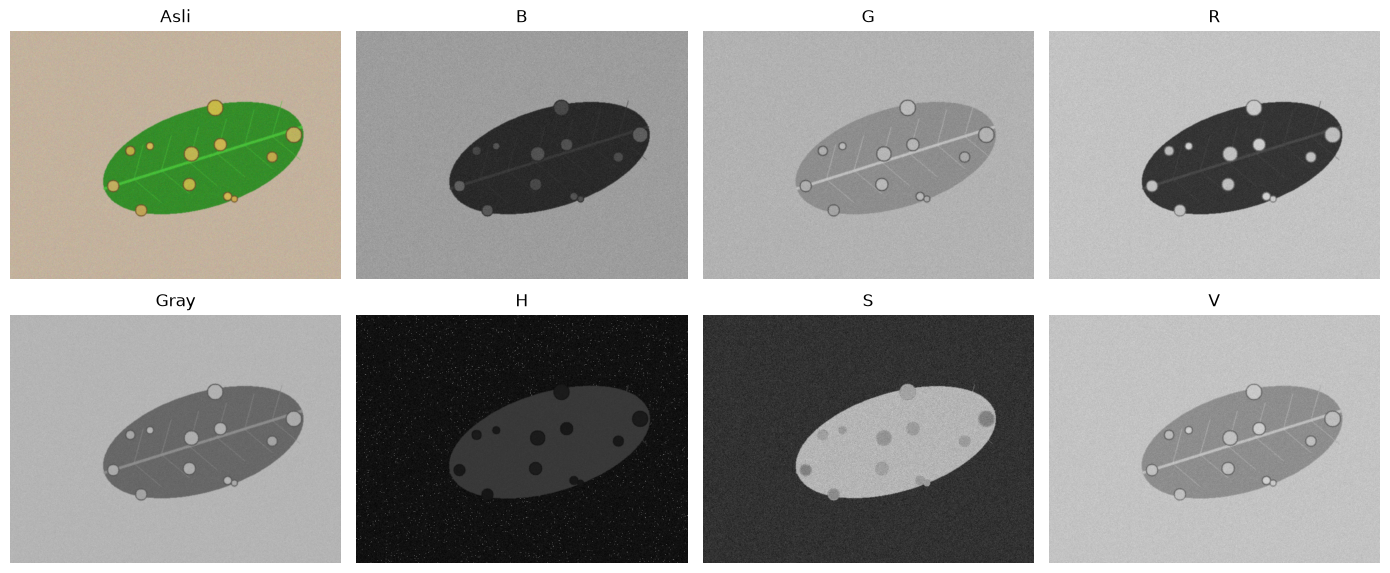

KB kanal B   : 3.62
KB kanal G   : 0.94
KB kanal R   : 13.38
KB kanal Gray: 5.50
KB kanal H   : 11.74
KB kanal S   : 2.44
KB kanal V   : 2.45


In [7]:
import sys
import os
import cv2
import numpy as np

sys.path.append(os.path.abspath("../src"))

from utils_cv import baca, kontras_bercak, tampil

nama = "teh_041.png" # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [8]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=5.91
fx=0.2: ukuran (96, 128), KB=5.27
fx=0.1: ukuran (48, 64), KB=3.59
fx=0.05: ukuran (24, 32), KB=1.79
k=1: 2 level, KB=3.75
k=2: 3 level, KB=3.75
k=3: 5 level, KB=4.83
k=4: 9 level, KB=5.56
k=8: 122 level, KB=5.50


In [9]:
import pandas as pd
import cv2  # Pastikan cv2 dan fungsi pendukung sudah di-import/didefinisikan

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {
        "B": b, 
        "G": g, 
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h, 
        "S": s, 
        "V": v
    }

label = pd.read_csv("../data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.01  0.47   5.34  1.60  4.61  0.91  0.94
gelap           1.24  1.32  11.18  4.59  6.65  0.96  3.15
kontras_rendah  0.94  0.43   3.95  2.23  2.07  0.25  1.37
normal          2.83  0.77  10.84  4.86  8.89  1.99  2.32
terang          2.28  0.62   7.11  3.74  5.52  0.97  2.00
